In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

In [2]:
proj_data = pd.read_csv(r"D:\Ml_Projects\customer_churn_pridiction\customerChurn_dataset\customer_churn_dataset-training-master.csv")

In [3]:
proj_data

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.00,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.00,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.00,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.00,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.00,20.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
440828,449995.0,42.0,Male,54.0,15.0,1.0,3.0,Premium,Annual,716.38,8.0,0.0
440829,449996.0,25.0,Female,8.0,13.0,1.0,20.0,Premium,Annual,745.38,2.0,0.0
440830,449997.0,26.0,Male,35.0,27.0,1.0,5.0,Standard,Quarterly,977.31,9.0,0.0
440831,449998.0,28.0,Male,55.0,14.0,2.0,0.0,Standard,Quarterly,602.55,2.0,0.0


In [4]:
proj_data.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [5]:
proj_data.tail()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
440828,449995.0,42.0,Male,54.0,15.0,1.0,3.0,Premium,Annual,716.38,8.0,0.0
440829,449996.0,25.0,Female,8.0,13.0,1.0,20.0,Premium,Annual,745.38,2.0,0.0
440830,449997.0,26.0,Male,35.0,27.0,1.0,5.0,Standard,Quarterly,977.31,9.0,0.0
440831,449998.0,28.0,Male,55.0,14.0,2.0,0.0,Standard,Quarterly,602.55,2.0,0.0
440832,449999.0,31.0,Male,48.0,20.0,1.0,14.0,Premium,Quarterly,567.77,21.0,0.0


In [6]:
proj_data.describe()


,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000
mean,225398.667955,39.373153,31.256336,15.807494,3.604437,12.965722,631.616223,14.480868,0.567107
std,129531.918550,12.442369,17.255727,8.586242,3.070218,8.258063,240.803001,8.596208,0.495477
min,2.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,113621.750000,29.000000,16.000000,9.000000,1.000000,6.000000,480.000000,7.000000,0.000000
50%,226125.500000,39.000000,32.000000,16.000000,3.000000,12.000000,661.000000,14.000000,1.000000
75%,337739.250000,48.000000,46.000000,23.000000,6.000000,19.000000,830.000000,22.000000,1.000000
max,449999.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [13]:
proj_data.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,440832.0,225398.667955,129531.918550,2.0,113621.75,226125.5,337739.25,449999.0
Age,440832.0,39.373153,12.442369,18.0,29.00,39.0,48.00,65.0
Tenure,440832.0,31.256336,17.255727,1.0,16.00,32.0,46.00,60.0
Usage Frequency,440832.0,15.807494,8.586242,1.0,9.00,16.0,23.00,30.0
Support Calls,440832.0,3.604437,3.070218,0.0,1.00,3.0,6.00,10.0
Payment Delay,440832.0,12.965722,8.258063,0.0,6.00,12.0,19.00,30.0
Total Spend,440832.0,631.616223,240.803001,100.0,480.00,661.0,830.00,1000.0
Last Interaction,440832.0,14.480868,8.596208,1.0,7.00,14.0,22.00,30.0
Churn,440832.0,0.567107,0.495477,0.0,0.00,1.0,1.00,1.0


In [15]:
proj_data.shape

(440833, 12)

In [17]:
proj_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440833 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  object 
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  object 
 8   Contract Length    440832 non-null  object 
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), object(3)
memory usage: 40.4+ MB


In [19]:
proj_data.isnull().sum()

CustomerID           1
Age                  1
Gender               1
Tenure               1
Usage Frequency      1
Support Calls        1
Payment Delay        1
Subscription Type    1
Contract Length      1
Total Spend          1
Last Interaction     1
Churn                1
dtype: int64

In [21]:
proj_data.duplicated().sum()

0

In [22]:
proj_data[proj_data.isnull().any(axis=1)]

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
199295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
proj_data=proj_data.dropna()

In [25]:
proj_data.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [27]:
## Outliers Processsing 

In [30]:
numeric_features = {
    "Age",
    "Tenure",
    "Usage Frequency",
    "Support Calls",
    "Payment Delay",
    "Total Spend",
    "Last Interaction",
}

In [33]:
categorical_features = {
    "Gender",
    "Subscription Type",
    "Contract Length",
}

In [35]:
outlier_summary =[]

for column in numeric_features:
    Q1 = proj_data[column].quantile(0.25)
    Q3 = proj_data[column].quantile(0.75)
    IQR = Q3- Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outlier_count = (
        (proj_data[column] < lower_bound) |
        (proj_data[column]> upper_bound)
    ).sum()
    outlier_percentage = (outlier_count/len(proj_data)) * 100

In [37]:
outlier_summary.append({
    "feature":column,
    "outliers": outlier_count,
    "percentage":round(outlier_percentage, 2)
    
})

In [39]:
outlier_summary

[{'feature': 'Age', 'outliers': 0, 'percentage': 0.0}]

In [41]:
outlier_df = pd.DataFrame(outlier_summary)

In [43]:
outlier_df

,feature,outliers,percentage
0,Age,0,0.0


##  Target Analysis phase

In [46]:
proj_data["Churn"].head()

0    1.0
1    1.0
2    1.0
3    1.0
4    1.0
Name: Churn, dtype: float64

In [48]:
target_count =proj_data["Churn"].value_counts()

In [50]:
target_count

Churn
1.0    249999
0.0    190833
Name: count, dtype: int64

In [52]:
target_percentage = proj_data["Churn"].value_counts(normalize=True) * 100

In [54]:
target_percentage

Churn
1.0    56.71072
0.0    43.28928
Name: proportion, dtype: float64

Text(0, 0.5, 'Customer count')

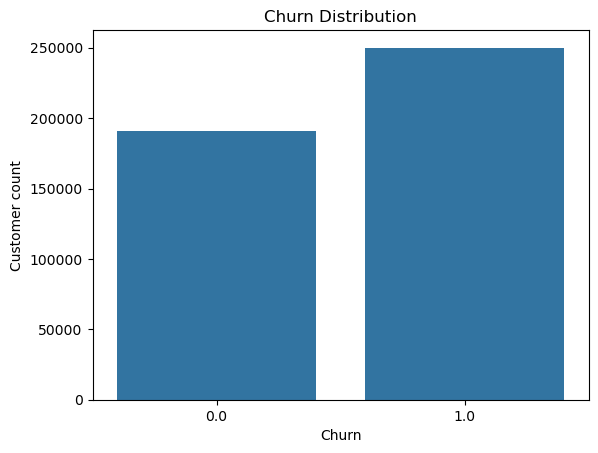

In [56]:
sns.countplot(x="Churn",data=proj_data)
plt.title("Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Customer count")

In [57]:
X = proj_data.drop(["Churn","CustomerID"], axis=1)
y = proj_data["Churn"]

In [58]:
y.value_counts()

Churn
1.0    249999
0.0    190833
Name: count, dtype: int64

In [59]:
X.dtypes

Age                  float64
Gender                object
Tenure               float64
Usage Frequency      float64
Support Calls        float64
Payment Delay        float64
Subscription Type     object
Contract Length       object
Total Spend          float64
Last Interaction     float64
dtype: object

In [60]:
numeric_features = X.select_dtypes(
    include=["float64"]
).columns

categorical_features=X.select_dtypes(
    include=["object"]
).columns

In [61]:
numeric_features

Index(['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay',
       'Total Spend', 'Last Interaction'],
      dtype='object')

In [62]:
categorical_features

Index(['Gender', 'Subscription Type', 'Contract Length'], dtype='object')

## Numeric features analysis

In [71]:
proj_data[numeric_features].describe()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
count,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000
mean,39.373153,31.256336,15.807494,3.604437,12.965722,631.616223,14.480868
std,12.442369,17.255727,8.586242,3.070218,8.258063,240.803001,8.596208
min,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000
25%,29.000000,16.000000,9.000000,1.000000,6.000000,480.000000,7.000000
50%,39.000000,32.000000,16.000000,3.000000,12.000000,661.000000,14.000000
75%,48.000000,46.000000,23.000000,6.000000,19.000000,830.000000,22.000000
max,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000


array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Tenure'}>,
        <Axes: title={'center': 'Usage Frequency'}>],
       [<Axes: title={'center': 'Support Calls'}>,
        <Axes: title={'center': 'Payment Delay'}>,
        <Axes: title={'center': 'Total Spend'}>],
       [<Axes: title={'center': 'Last Interaction'}>, <Axes: >, <Axes: >]],
      dtype=object)

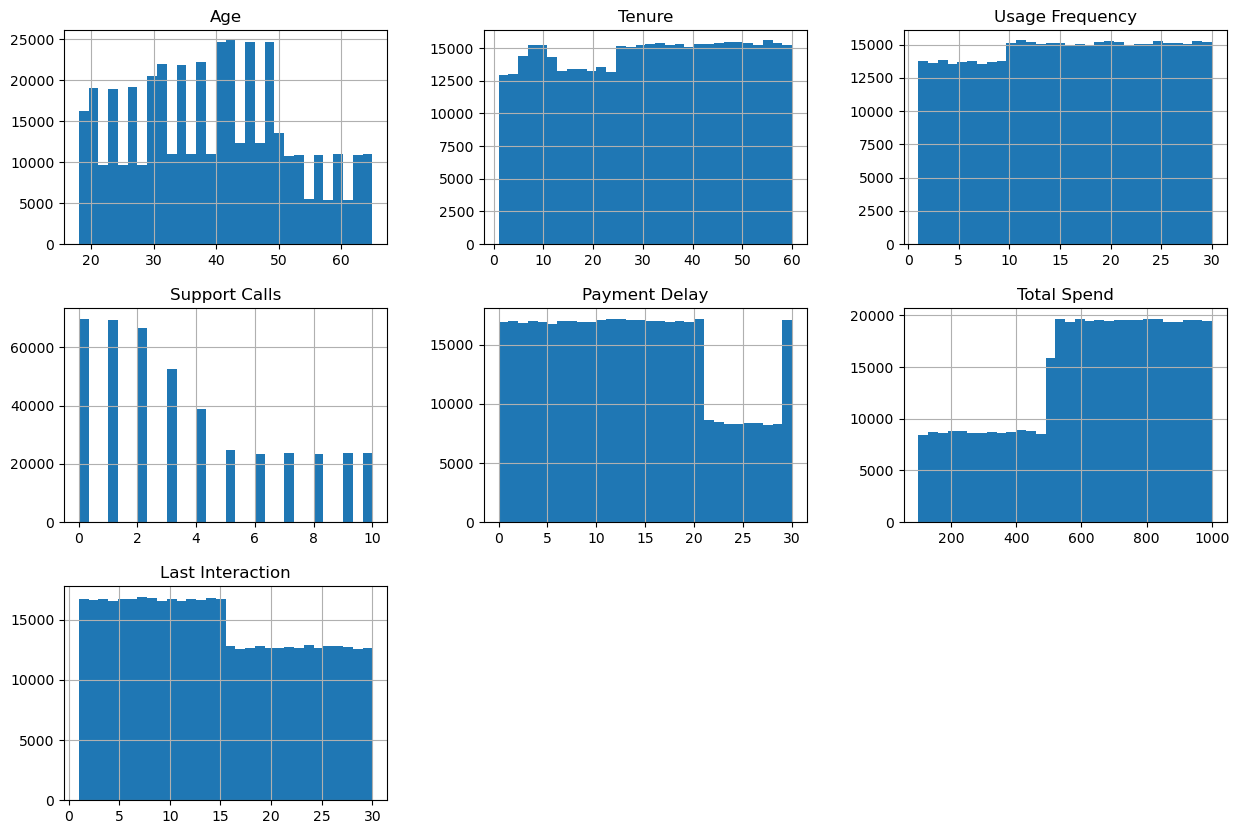

In [73]:
proj_data[numeric_features].hist(
    figsize=(15,10),
    bins=30
)

In [74]:
skewness = proj_data[numeric_features].skew()
skewness.sort_values(ascending=False)

Support Calls       0.666809
Payment Delay       0.267407
Last Interaction    0.176774
Age                 0.162016
Usage Frequency    -0.043473
Tenure             -0.061402
Total Spend        -0.457174
dtype: float64

In [75]:
proj_data.groupby("Churn")[numeric_features].mean()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
Churn,,,,,,,
0.0,36.262973,32.281754,16.260552,1.586418,10.015500,749.953111,13.008804
1.0,41.747263,30.473598,15.461658,5.144861,15.217729,541.285528,15.604546


### Compare Churn Rate (numeric)

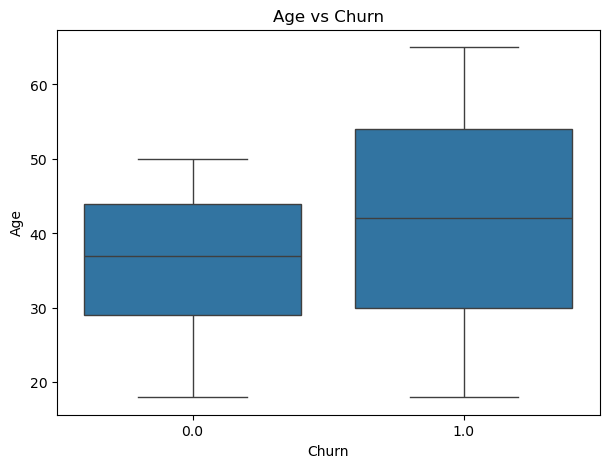

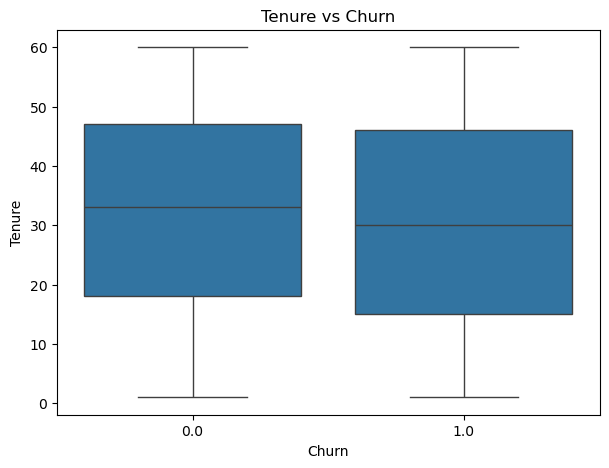

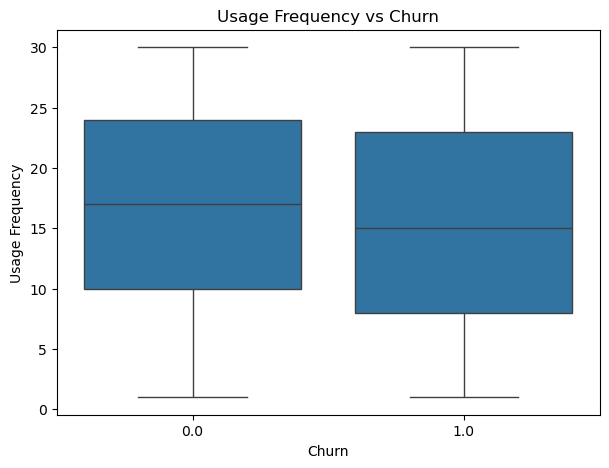

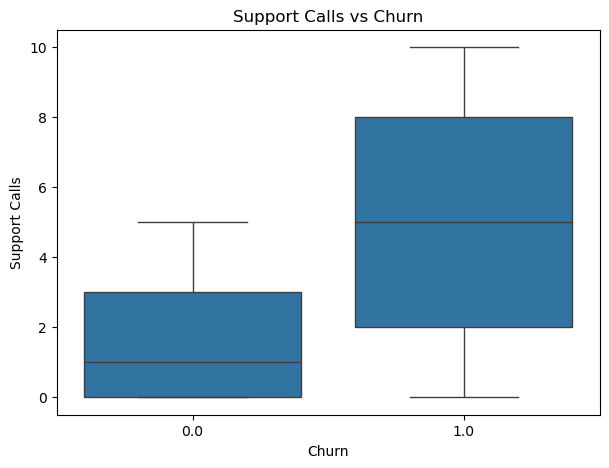

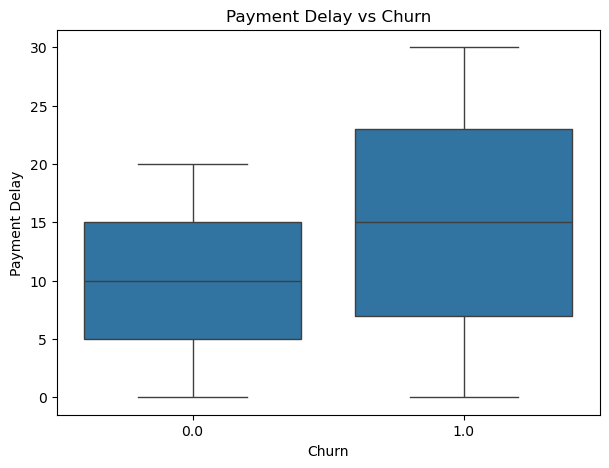

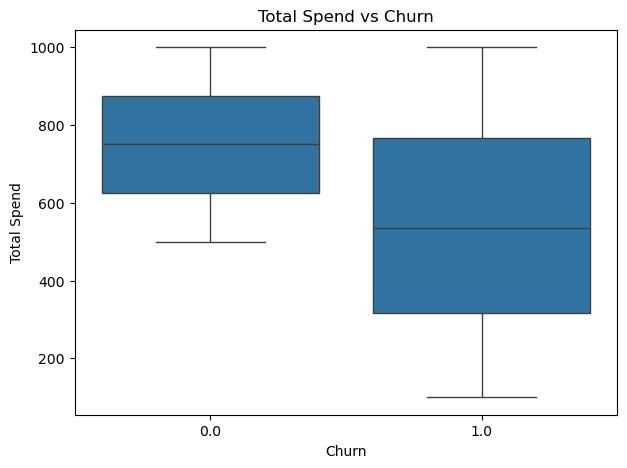

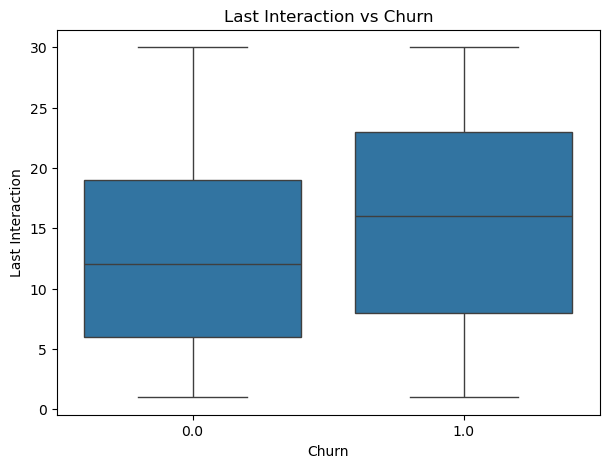

In [77]:
for column in numeric_features:
    plt.figure(figsize=(7,5))
    sns.boxplot(
    data=proj_data,
    x="Churn",
    y=column
    )
    plt.title(f"{column} vs Churn")
    plt.xlabel("Churn")
    plt.ylabel(column)
    

### Compare Churn Rate (Categorical)

In [80]:
for column in categorical_features:
    print(f"\n{column}")



Gender

Subscription Type

Contract Length


In [83]:
proj_data[column].unique()

array(['Annual', 'Monthly', 'Quarterly'], dtype=object)

In [84]:
proj_data["Gender"].value_counts()

Gender
Male      250252
Female    190580
Name: count, dtype: int64

In [85]:
proj_data["Subscription Type"].value_counts()

Subscription Type
Standard    149128
Premium     148678
Basic       143026
Name: count, dtype: int64

In [86]:
proj_data["Contract Length"].value_counts()

Contract Length
Annual       177198
Quarterly    176530
Monthly       87104
Name: count, dtype: int64

In [87]:
pd.crosstab(
    proj_data["Contract Length"],
    proj_data["Churn"],
    normalize="index"
) * 100

Churn,0.0,1.0
Contract Length,,
Annual,53.923859,46.076141
Monthly,0.000000,100.000000
Quarterly,53.974395,46.025605


<Axes: xlabel='Contract Length', ylabel='count'>

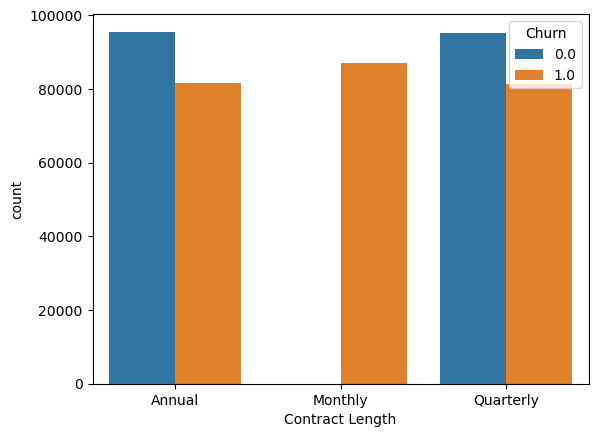

In [88]:
sns.countplot(
    data=proj_data,
    x="Contract Length",
    hue="Churn"
)

In [89]:
pd.crosstab(
    proj_data["Subscription Type"],
    proj_data["Churn"],
    normalize="index"
) * 100

Churn,0.0,1.0
Subscription Type,,
Basic,41.821767,58.178233
Premium,44.058300,55.941700
Standard,43.930047,56.069953


<Axes: xlabel='Subscription Type', ylabel='count'>

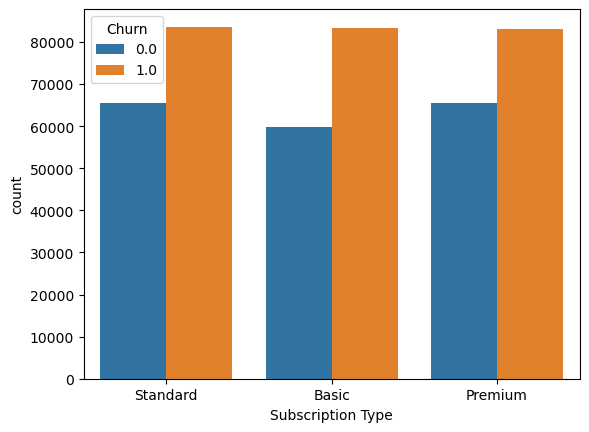

In [90]:
sns.countplot(
    data=proj_data,
    x="Subscription Type",
    hue="Churn"
)

In [91]:
pd.crosstab(
    proj_data["Gender"],
    proj_data["Churn"],
    normalize ="index"
) * 100

Churn,0.0,1.0
Gender,,
Female,33.330885,66.669115
Male,50.873120,49.126880


<Axes: xlabel='Gender', ylabel='count'>

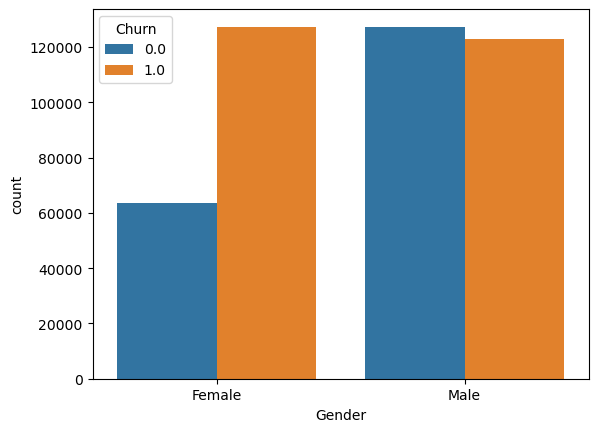

In [92]:
sns.countplot(
    data=proj_data,
    x="Gender",
    hue="Churn"
)

## Data Leakage Analysis

In [94]:
proj_data.columns.tolist()

['CustomerID',
 'Age',
 'Gender',
 'Tenure',
 'Usage Frequency',
 'Support Calls',
 'Payment Delay',
 'Subscription Type',
 'Contract Length',
 'Total Spend',
 'Last Interaction',
 'Churn']

In [95]:
target="Churn"

In [96]:
X = proj_data.drop(columns=["Churn",])

In [97]:
y = proj_data["Churn"]

## Train / Validation

#### Split correctly

In [100]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val  = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Preprocessing :  numeric scaling

###  categorical scaling :

In [103]:
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE   ## combile both dataset after processing 
from sklearn.impute import SimpleImputer   ## imputation
from sklearn.preprocessing import StandardScaler   ## Scaling
from sklearn.preprocessing import OneHotEncoder

In [104]:
### Numerical pipeline

In [105]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [106]:
### Categorical pipeline

In [107]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
    

In [108]:
###Combine both

In [109]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

### Balance Training Data and build model

In [111]:
## Train Logistic regression

model = Pipeline([
     ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier",LogisticRegression(max_iter=1000))
])

In [ ]:
model.fit(X_train, y_train)

In [ ]:
y_val_pred = model.predict(X_val)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, classification_report

In [ ]:
print("accuracy :", accuracy_score(y_val, y_val_pred))
print("Precision :", precision_score(y_val, y_val_pred))
print("recall :", recall_score(y_val, y_val_pred))
print("f1 score:", f1_score(y_val, y_val_pred))

In [ ]:
cm = confusion_matrix(y_val, y_val_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churn", "Churn"]
)

disp.plot()
plt.title("Confusion matrix - Logistic Regression")

In [ ]:
print("\nClassification report: ")
print(classification_report(y_val, y_val_pred))

In [ ]:
y_val_proba = model.predict_proba(X_val)[:,1]
fpr, tpr, thresholds = roc_curve(y_val, y_val_proba)
auc_score = roc_auc_score(y_val, y_val_proba)
("ROC-AUC Score:", auc_score )

In [ ]:
plt.figure(figsize=(7,5))

plt.plot(fpr, tpr, label=f"Logistic Regression(AUC = {auc_score:.3f})")
plt.plot([0,1],[0,1], linestyle="--")

plt.xlabel("False Positive Rate ")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve")
plt.legend()

In [ ]:
classification_report(
    y_val, 
    y_val_pred,
    target_names=["Not Churn", "Churn"]
)

### Decision tree model train

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

dt_model.fit(X_train, y_train)

y_val_pred_dt =  dt_model.predict(X_val)

print("Confusion Matrix: ")
print(confusion_matrix(y_val, y_val_pred_dt))

print("\nClassification Report: ")
print(classification_report(y_val, y_val_pred_dt))

#### predict in both model and compare this

In [ ]:
# logistic regression predictions
y_val_pred_lr = model.predict(X_val)

# Decision Tree predictions
y_val_pred_dt = dt_model.predict(X_val)

#compare both models
comparison = pd.DataFrame({
    "Metric":["Accuracy", "Prediction", "Recall", "F1-Score"],"Logistic Regression":[
        accuracy_score(y_val, y_val_pred_lr),
        precision_score(y_val, y_val_pred_lr),
        recall_score(y_val, y_val_pred_lr),
        f1_score(y_val, y_val_pred_lr)
    ],
    "Decision Tree":[
        accuracy_score(y_val, y_val_pred_dt),
        precision_score(y_val, y_val_pred_dt),
        recall_score(y_val, y_val_pred_dt),
        f1_score(y_val, y_val_pred_dt)
    ]
})

print(comparison.round(4))

In [ ]:
## check training vs validation performance
y_train_pred_dt =dt_model.predict(X_train)

print("Decision Tree Training Accuracy:",
      accuracy_score(y_train, y_train_pred_dt))
print("Decision Tree Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_dt))

In [ ]:
## remove labels

In [ ]:
## check wheather the tree is overfitting
tree = dt_model.named_steps["classifier"]

print("Tree depth:", tree.get_depth())
print("Number of leaves:", tree.get_n_leaves())
print("Number of features:", X_train.shape[1])

In [ ]:
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

print("\nChurn in training features:", "Churn" in X_train.columns)
print("Churn in validation features:", "Churn" in X_val.columns)

In [ ]:
train_rows = pd.MultiIndex.from_frame(X_train)
val_rows = pd.MultiIndex.from_frame(X_val)

print("Validation rows also present in training:",
      val_rows.isin(train_rows).sum())

In [ ]:
print("Validation accuracy:",
      accuracy_score(y_val, y_val_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_dt))

print("\nIncorrect predictions:")
print((y_val != y_val_pred_dt).sum())

print("\nTotal validation rows:", len(y_val))


In [ ]:
tree = dt_model.named_steps["classifier"]

print("Tree depth:", tree.get_depth())
print("Number of leaves:", tree.get_n_leaves())

In [ ]:
from sklearn.metrics import accuracy_score

y_train_pred_dt = dt_model.predict(X_train)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_dt))

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_dt))

In [ ]:
import pandas as pd

feature_names = dt_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = pd.Series(
    tree.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importance.head(15))

In [ ]:
# Compare the feature distributions for each churn class
for col in [
    "Support Calls",
    "Total Spend",
    "Payment Delay",
    "Contract Length"
]:
    print(f"\n--- {col} ---")
    print(
        proj_data.groupby("Churn")[col]
        .agg(["mean", "median", "min", "max"])
    )

In [ ]:
print("Features:", X_train.columns.tolist())

print("\nTarget distribution in training:")
print(y_train.value_counts())

print("\nTarget distribution in validation:")
print(y_val.value_counts())

print("\nDuplicate rows in original dataset:",
      proj_data.duplicated().sum())

In [ ]:
check_data = X_train.copy()
check_data["_target"] = y_train.to_numpy()

label_counts = check_data.groupby(
    list(X_train.columns),
    dropna=False
)["_target"].nunique()

print("Feature groups with conflicting labels:",
      (label_counts > 1).sum())

In [ ]:
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

dt_model.fit(X_train, y_train)

y_val_pred_dt = dt_model.predict(X_val)

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_dt))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_dt))

In [ ]:
test_data = pd.read_csv(r"D:\Ml_Projects\customer_churn_pridiction\customerChurn_dataset\customer_churn_dataset-testing-master.csv")

In [ ]:
test_data

In [ ]:
test_data.shape

In [ ]:
test_data.head()

In [ ]:
X_test = test_data.drop(columns=["Churn", "CustomerID"])
y_test = test_data["Churn"]

In [ ]:
y_test_pred = model.predict(X_test)

In [ ]:
y_test_proba = model.predict_proba(X_test)[:,1]

In [ ]:
print("accuracy :", accuracy_score(y_test, y_test_pred))
print("Precision :", precision_score(y_test, y_test_pred))
print("recall :", recall_score(y_test, y_test_pred))
print("f1 score:", f1_score(y_test, y_test_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_test_proba))

## Compare train and test data

In [ ]:
print("Train data Shape:", proj_data.shape)
print("Test data Shape:", test_data.shape)

In [ ]:
proj_data["Churn"].value_counts(normalize=True)*100

In [ ]:
test_data["Churn"].value_counts(normalize=True)*100

In [ ]:
proj_data[numeric_features].describe().T 

In [ ]:
test_data[numeric_features].describe().T 

In [ ]:
proj_data

In [ ]:
model.predict([[

In [ ]:
# row wise testing data on both model
# support call row check